# Lab 5 — Speech enhancement (4.1–4.3)

**Clean + noise → noisy 0/5/10 dB → SS / Wiener → so phổ với clean.** Thuật toán chỉ nhận noisy; clean dùng để đánh giá. SS chọn **một cấu hình tốt nhất theo SNR trung bình trên dev**, khóa trước khi chạy test. “Tốt nhất” ở đây không đồng nghĩa chất lượng nghe tốt nhất.

Dữ liệu/giấy phép: `data/README.md`.

In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd().resolve()
if not (ROOT/'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'.cache/matplotlib'))
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from src.experiments import select_ss_config, run_enhancement_cases
from src.visualization import (plot_dev_selection, plot_snr_summary,
                               plot_spectrum_comparison, plot_comparison)

CONFIG = dict(clean='spk01_test_01.wav', noises=['rain', 'vacuum_cleaner'],
              snrs=[0,5,10], betas=[1.,1.5,2.], floors=[0.,.01,.05], demo_snr=5)
STFT = dict(n_fft=512, win_length=400, hop_length=160)
NOISE_PATHS = [ROOT/f'data/noise/{name}.wav' for name in CONFIG['noises']]
AUDIO, FIGURES = ROOT/'results/audio/enhancement', ROOT/'results/figures/enhancement'
for folder in [AUDIO, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

### 1. Chọn cấu hình SS trên dev

6 dev utterances × 2 noise × 3 SNR cho mỗi cấu hình. Chọn β/γ theo SNR_out trung bình cao nhất; Wiener dùng cấu hình decision-directed cố định (0,9). Cả hai tự ước lượng noise từ các frame năng lượng thấp của noisy; không nhận noise gốc, α hay SNR mục tiêu.

SS được chọn: {'beta': 2.0, 'floor': 0.01}


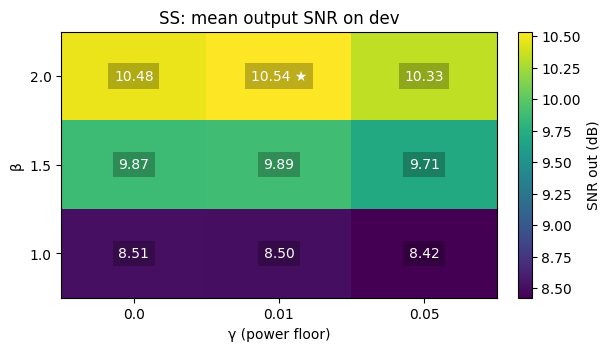

In [2]:
best_ss, dev_summary, dev_trials = select_ss_config(
    list((ROOT/'data/clean').glob('*_dev_*.wav')), NOISE_PATHS,
    CONFIG['snrs'], CONFIG['betas'], CONFIG['floors'], STFT)
dev_summary.to_csv(AUDIO/'dev_selection.csv', index=False)
dev_trials.to_csv(AUDIO/'dev_trials.csv', index=False)
(AUDIO/'config.json').write_text(json.dumps(
    dict(experiment=CONFIG, stft=STFT, ss=best_ss,
         wiener=dict(decision_directed=0.9, amplitude_floor=0.05),
         selection='maximum mean dev SNR; frozen before test'), indent=2))
print('SS được chọn:', best_ss)
fig = plot_dev_selection(dev_summary)
fig.savefig(FIGURES/'dev_selection.png', dpi=150)
plt.show()

### 2. Đánh giá test: noisy / SS tốt nhất / Wiener

Tạo noisy ở 0/5/10 dB, khử nhiễu độc lập, lưu WAV với cùng gain tránh clipping; đo SNR lại từ WAV. Cột cao hơn nghĩa là sai số so với clean thấp hơn. Clean chính xác sẽ có SNR vô hạn nên không vẽ thành cột.

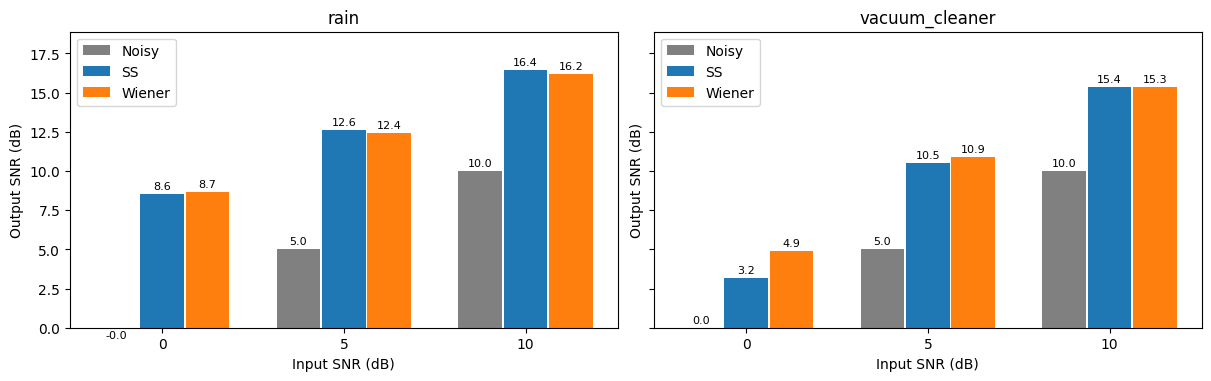

In [3]:
cases, metrics, sr = run_enhancement_cases(
    ROOT/'data/clean'/CONFIG['clean'], NOISE_PATHS, CONFIG['snrs'], best_ss, STFT, AUDIO)
fig = plot_snr_summary(metrics)
fig.savefig(FIGURES/'snr_comparison.png', dpi=150)
plt.show()

### 3. So phổ với ground truth

**Trái:** PSD tuyệt đối của clean/noisy/SS/Wiener trên cùng thang dB. Output gần đường clean hơn là dấu hiệu phù hợp về phổ, nhưng không đủ kết luận chất lượng. **Phải:** phổ sai số output − clean, càng thấp càng tốt. Không normalize riêng từng đường. Speech gốc 8 kHz nên ít năng lượng trên 4 kHz; thuật toán không dùng cutoff này.

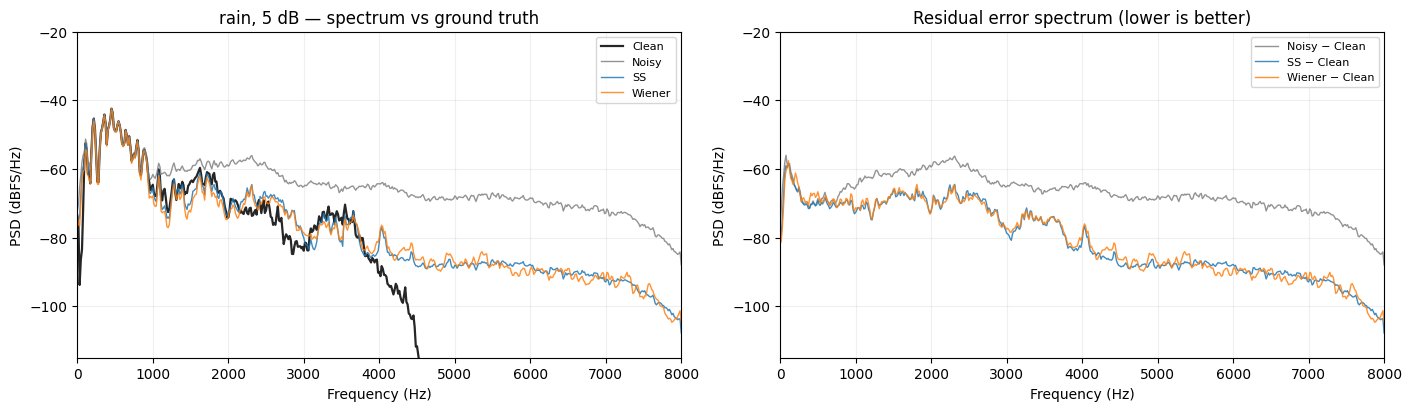

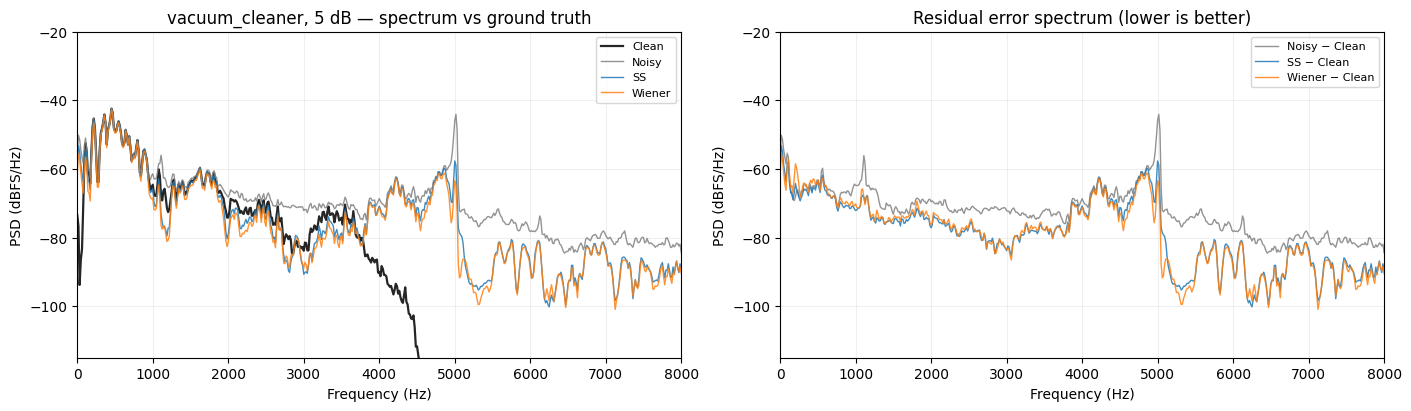

In [4]:
for noise_name in CONFIG['noises']:
    signals = cases[(noise_name, CONFIG['demo_snr'])]
    fig = plot_spectrum_comparison(signals, sr, f"{noise_name}, {CONFIG['demo_snr']} dB")
    fig.savefig(FIGURES/f'{noise_name}_spectrum.png', dpi=150)
    plt.show()

### 4. Spectrogram và audio tại cấu hình đã chọn

Cùng thang màu và gain, không normalize riêng. Đổi `demo_snr` và `demo_noise` bên dưới để xem trường hợp khác.

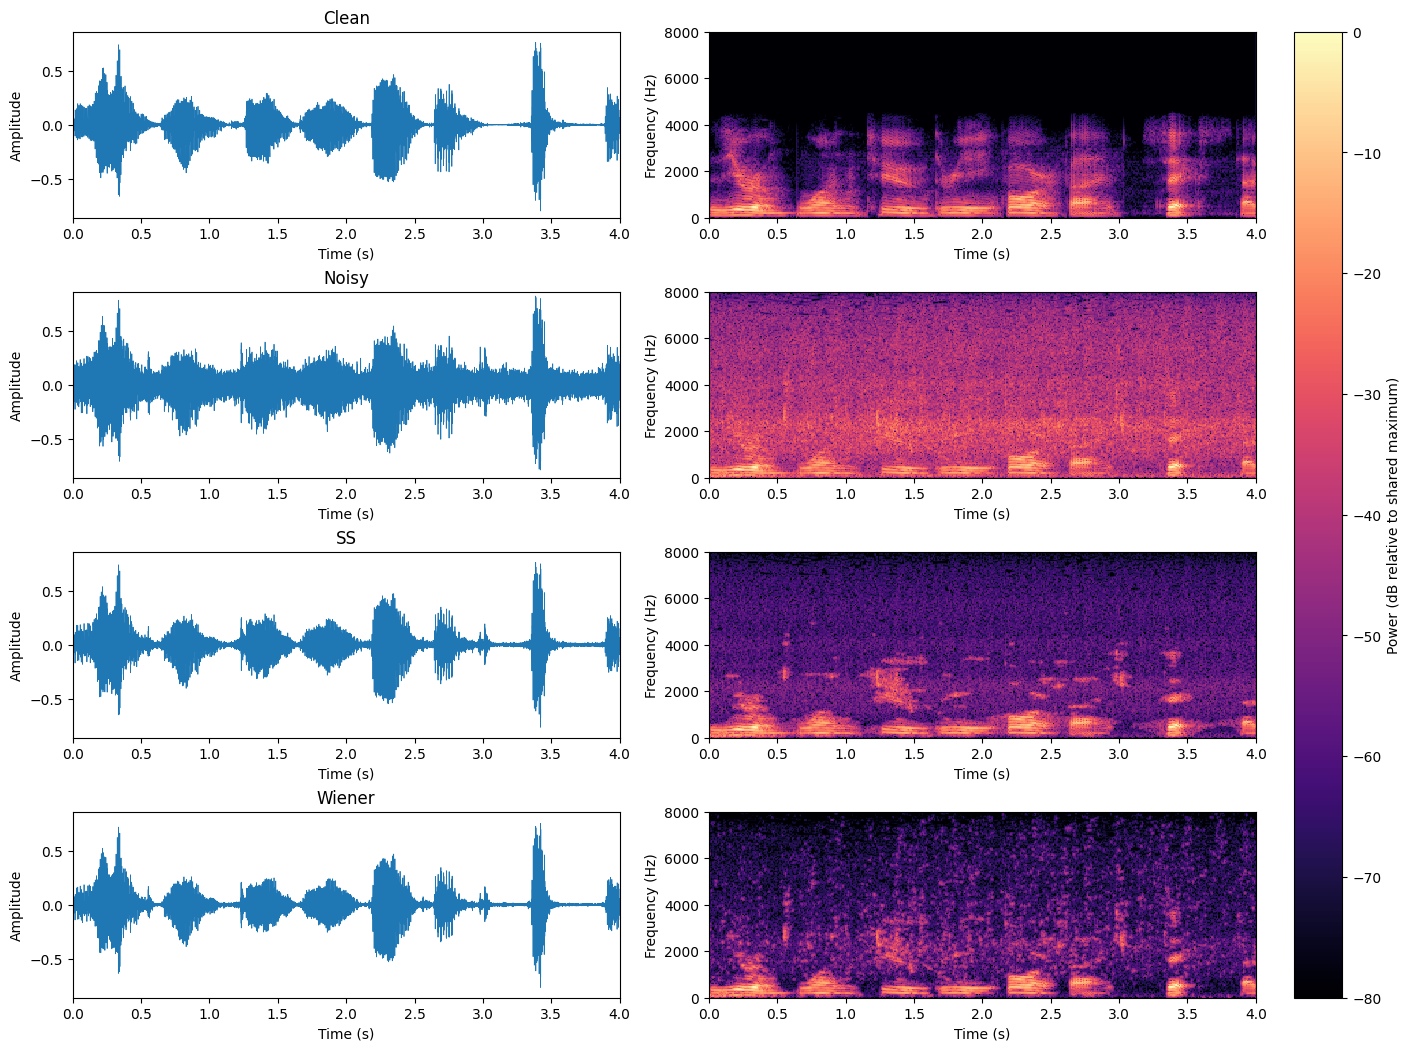

Clean


Noisy


SS


Wiener


In [5]:
demo_noise = CONFIG['noises'][0]
signals = cases[(demo_noise, CONFIG['demo_snr'])]
fig = plot_comparison(signals, sr, **STFT)
fig.savefig(FIGURES/f'{demo_noise}_spectrogram.png', dpi=150)
plt.show()
for label, x in signals.items():
    print(label)
    display(Audio(x, rate=sr, normalize=False))